# The Ultimate OpenCV 7-Day Bootcamp: Professional Mastery
Welcome to the comprehensive, professional-grade OpenCV training notebook for Team Chati Pati.
This resource is designed to transition you from a beginner to a computer vision professional ready for the final round of the Quera Image Processing Olympiad.

**Roadmap Overview:**
* **Day 1:** Image Processing Basics, Color Spaces, ROI, Histograms, Pixel Manipulation
* **Day 2:** Filtering & Thresholding, Noise Mitigation
* **Day 3:** Edge Detection, Gradients, Auto-Canny
* **Day 4:** Morphology, Contours, Connected Components
* **Day 5:** Hough Lines, Robust Geometry Algorithms
* **Day 6:** Perspective Transform, Synthetic Datasets, Evaluation Metrics
* **Day 7:** Phase 1 Project (End-to-End Expert Pipeline)

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import urllib.request
import math
import random

# Create directory for images
plt.rcParams['figure.figsize'] = (10, 6)

def show_image(img, title="Image", cmap=None):
    plt.figure(figsize=(6, 4))
    plt.imshow(img, cmap=cmap)
    plt.title(title)
    plt.axis('off')
    plt.show()


## Day 1 — Image Processing Basics & Expert Techniques
**Topics:** BGR / RGB, HSV, Grayscale, Resize, Crop / ROI, Histogram, Pixel manipulation

### 1. Image Sourcing & 5+ Reusable Core Functions
OpenCV reads color in **BGR** format, while libraries like Matplotlib expect **RGB**. 
* **HSV** (Hue, Saturation, Value) decouples color from lighting, crucial for robust segmentation.
* **Histograms** show pixel intensity distributions.
* **Resizing** with `cv2.INTER_AREA` is best for downsampling.

In [1]:
# Reusable Function 2: Load Image safely
def load_image(filepath, as_rgb=True):
    '''Loads an image safely. Converts to RGB by default.'''
    img = cv2.imread(filepath)
    if img is None: raise ValueError(f"Not found: {filepath}")
    if as_rgb: img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img

# Reusable Function 3: Resize keeping aspect ratio
def resize_keep_ratio(img, target_width=None, target_height=None):
    '''Resizes an image while preserving the aspect ratio.'''
    h, w = img.shape[:2]
    if target_width: 
        ratio = target_width / w
        dim = (target_width, int(h * ratio))
    else: 
        ratio = target_height / h
        dim = (int(w * ratio), target_height)
    return cv2.resize(img, dim, interpolation=cv2.INTER_AREA)

# Reusable Function 4: Extract Region of Interest (ROI)
def extract_roi(img, x, y, w, h):
    '''Extracts a sub-region from an image using Numpy slicing.'''
    return img[y:y+h, x:x+w]

# Reusable Function 5: Display multiple images
def show_images_grid(images, titles, rows, cols, figsize=(15, 10), cmap=None):
    '''Displays a list of images in a grid format.'''
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    if rows * cols == 1: axes = np.array([axes])
    for i, (img, title) in enumerate(zip(images, titles)):
        ax = axes.flatten()[i]
        ax.imshow(img, cmap=cmap)
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

### 2. Practice: Pixel Manipulation, Color Spaces & Histograms
Here we manipulate pixels, extract an ROI, compare RGB/BGR/HSV, and analyze color histograms.

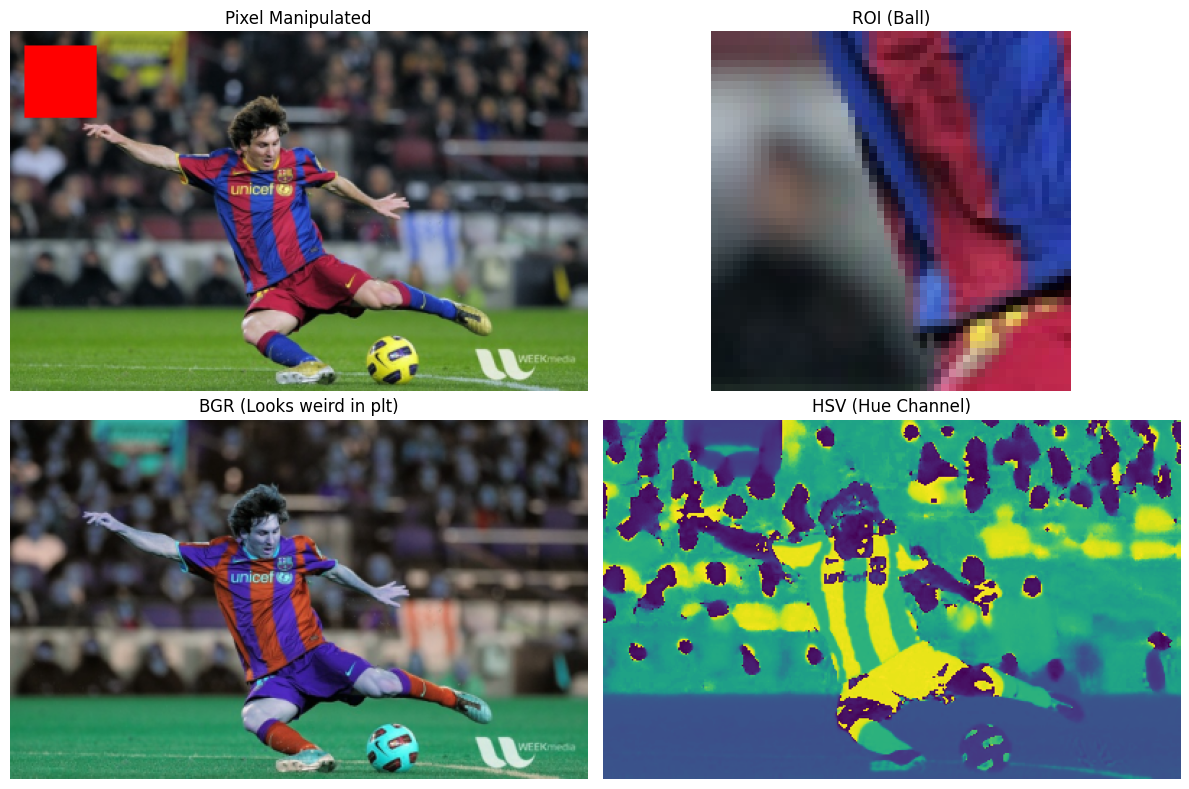

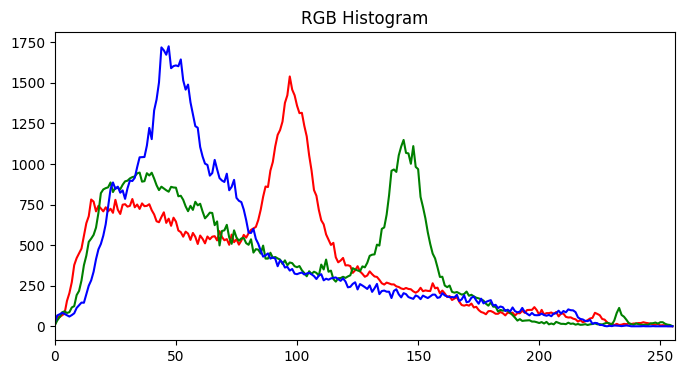

In [4]:
# Load Messi image and resize
img_messi = load_image('data/images/messi.jpg')
img_resized = resize_keep_ratio(img_messi, target_width=400)

# Pixel Manipulation: Draw a red square by directly modifying pixel values
img_pixel = img_resized.copy()
img_pixel[10:60, 10:60] = [255, 0, 0] # RGB Red

# Extract ROI (The soccer ball)
roi_ball = extract_roi(img_resized, x=135, y=140, w=50, h=50)

# Color Space Conversions
img_bgr = cv2.cvtColor(img_resized, cv2.COLOR_RGB2BGR)
img_hsv = cv2.cvtColor(img_resized, cv2.COLOR_RGB2HSV)

show_images_grid(
    [img_pixel, roi_ball, img_bgr, img_hsv[..., 0]], 
    ['Pixel Manipulated', 'ROI (Ball)', 'BGR (Looks weird in plt)', 'HSV (Hue Channel)'], 
    2, 2, figsize=(12, 8)
)

# Histogram Comparison
def plot_histograms(img_rgb):
    '''Generates and plots histograms for R, G, B channels.'''
    colors = ('r', 'g', 'b')
    plt.figure(figsize=(8, 4))
    for i, color in enumerate(colors):
        hist = cv2.calcHist([img_rgb], [i], None, [256], [0, 256])
        plt.plot(hist, color=color)
        plt.xlim([0, 256])
    plt.title('RGB Histogram')
    plt.show()

plot_histograms(img_resized)

## Day 2 — Filtering & Thresholding
**Topics:** Gaussian Blur, Median Blur, Bilateral Filter, Otsu Threshold, Adaptive Threshold

### 1. Noise Generation & Filtering
* **Gaussian Blur:** Best for Gaussian/normal sensor noise.
* **Median Blur:** Non-linear filter. Best for Salt & Pepper noise.
* **Bilateral Filter:** Edge-preserving blur.

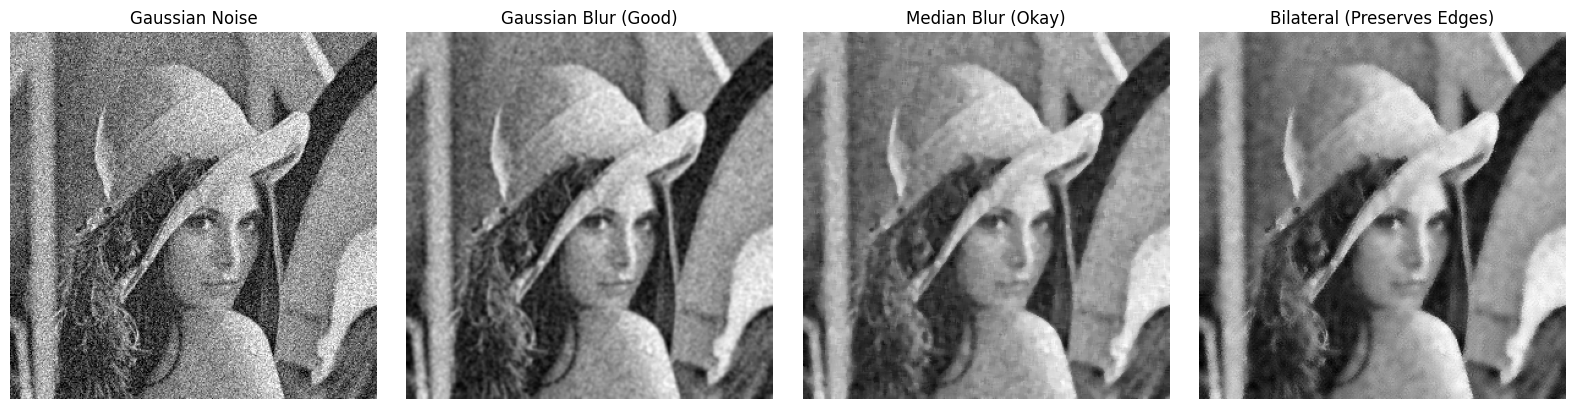

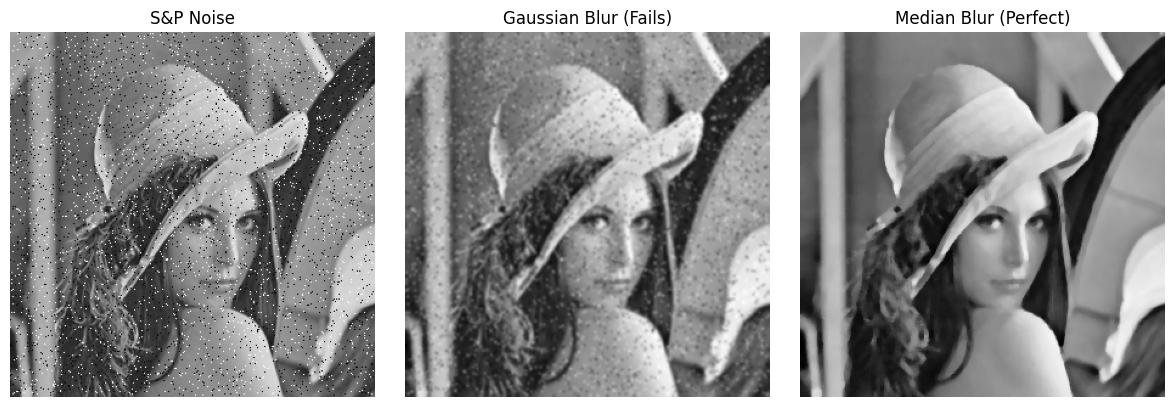

In [5]:
def add_gaussian_noise(image, mean=0, std=25):
    noise = np.random.normal(mean, std, image.shape).astype(np.float32)
    noisy = cv2.add(image.astype(np.float32), noise)
    return np.clip(noisy, 0, 255).astype(np.uint8)

def add_sp_noise(image, prob=0.05):
    noisy = np.copy(image)
    num_salt = np.ceil(prob * image.size * 0.5)
    num_pepper = np.ceil(prob * image.size * 0.5)
    
    coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape[:2]]
    noisy[tuple(coords)] = 255
    coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape[:2]]
    noisy[tuple(coords)] = 0
    return noisy

img_lena = cv2.cvtColor(load_image('data/images/lena.jpg'), cv2.COLOR_RGB2GRAY)
img_lena = resize_keep_ratio(img_lena, target_width=300)

img_gauss_noise = add_gaussian_noise(img_lena, std=30)
img_sp_noise = add_sp_noise(img_lena, prob=0.05)

# Visual Comparison Report (Evaluation)
gauss_on_gauss = cv2.GaussianBlur(img_gauss_noise, (5, 5), 0)
median_on_gauss = cv2.medianBlur(img_gauss_noise, 5)
bilateral_on_gauss = cv2.bilateralFilter(img_gauss_noise, 9, 75, 75)

gauss_on_sp = cv2.GaussianBlur(img_sp_noise, (5, 5), 0)
median_on_sp = cv2.medianBlur(img_sp_noise, 5)

show_images_grid(
    [img_gauss_noise, gauss_on_gauss, median_on_gauss, bilateral_on_gauss],
    ['Gaussian Noise', 'Gaussian Blur (Good)', 'Median Blur (Okay)', 'Bilateral (Preserves Edges)'],
    1, 4, cmap='gray', figsize=(16, 4)
)

show_images_grid(
    [img_sp_noise, gauss_on_sp, median_on_sp],
    ['S&P Noise', 'Gaussian Blur (Fails)', 'Median Blur (Perfect)'],
    1, 3, cmap='gray', figsize=(12, 4)
)

### 2. Thresholding
Converting grayscale to binary using Otsu and Adaptive techniques.

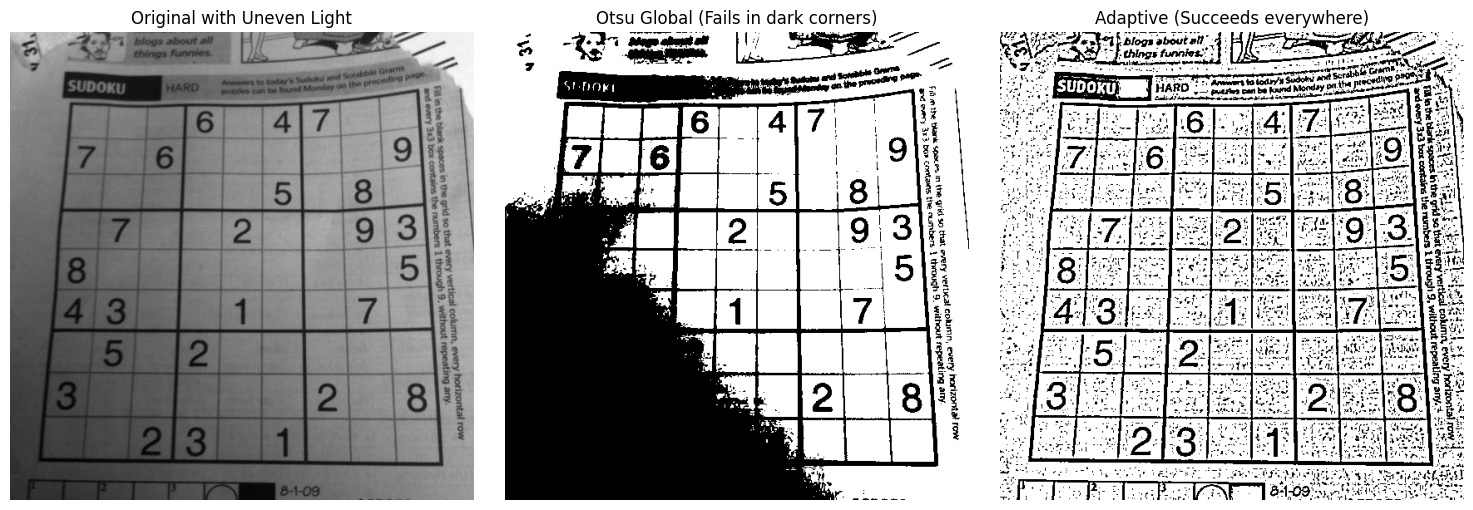

In [6]:
img_sudoku = cv2.cvtColor(load_image('data/images/sudoku.png'), cv2.COLOR_RGB2GRAY)
_, th_otsu = cv2.threshold(img_sudoku, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
th_adaptive = cv2.adaptiveThreshold(img_sudoku, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2)

show_images_grid(
    [img_sudoku, th_otsu, th_adaptive],
    ['Original with Uneven Light', "Otsu Global (Fails in dark corners)", 'Adaptive (Succeeds everywhere)'],
    1, 3, cmap='gray', figsize=(15, 5)
)

## Day 3 — Edge Detection
**Topics:** Sobel, Scharr, Laplacian, Canny

### 1. Gradients and Canny Pipeline

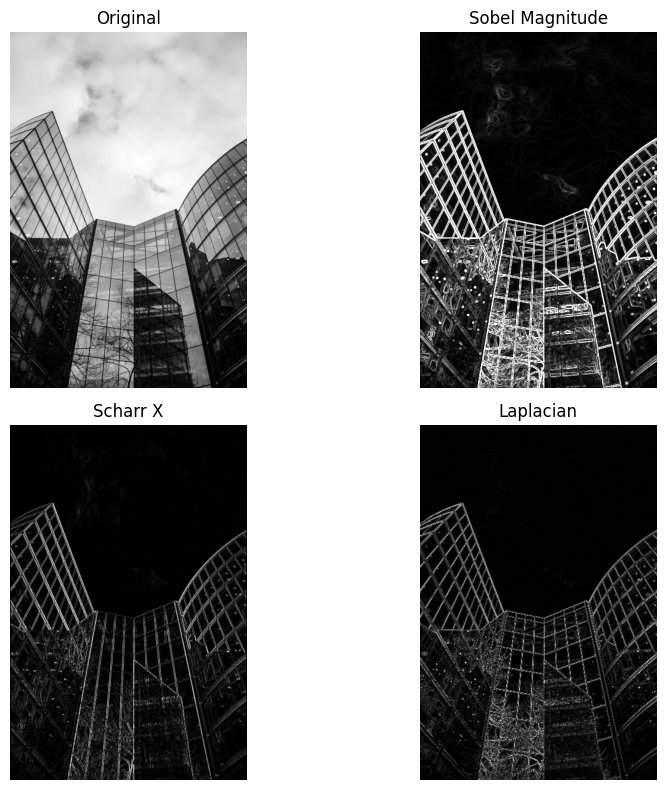

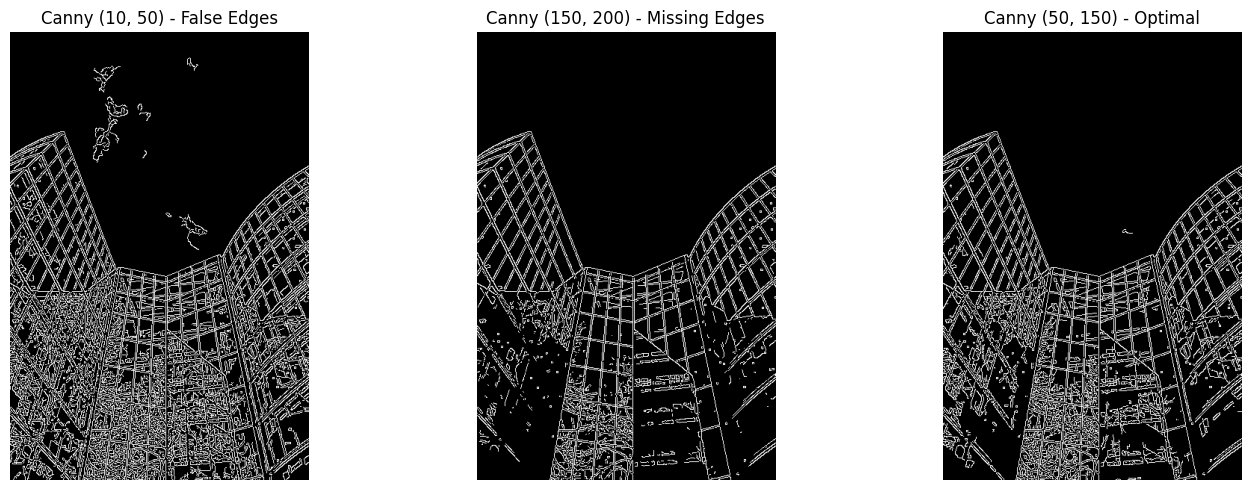

In [7]:
img_build = cv2.cvtColor(load_image('data/images/building.jpg'), cv2.COLOR_RGB2GRAY)
img_build = resize_keep_ratio(img_build, target_width=400)

sobel_x = cv2.Sobel(img_build, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img_build, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag = np.uint8(np.clip(cv2.magnitude(sobel_x, sobel_y), 0, 255))
scharr_x = cv2.Scharr(img_build, cv2.CV_64F, 1, 0)
laplacian = cv2.convertScaleAbs(cv2.Laplacian(img_build, cv2.CV_64F))

show_images_grid([img_build, sobel_mag, np.abs(scharr_x), laplacian],
    ['Original', 'Sobel Magnitude', 'Scharr X', 'Laplacian'], 2, 2, cmap='gray', figsize=(10, 8))

canny_low = cv2.Canny(img_build, 10, 50)
canny_high = cv2.Canny(img_build, 150, 200)
canny_opt = cv2.Canny(img_build, 50, 150)

show_images_grid([canny_low, canny_high, canny_opt],
    ['Canny (10, 50) - False Edges', 'Canny (150, 200) - Missing Edges', 'Canny (50, 150) - Optimal'],
    1, 3, cmap='gray', figsize=(15, 5))

## Day 4 — Morphology & Contours
**Topics:** Erosion, Dilation, Opening, Closing, Connected Components

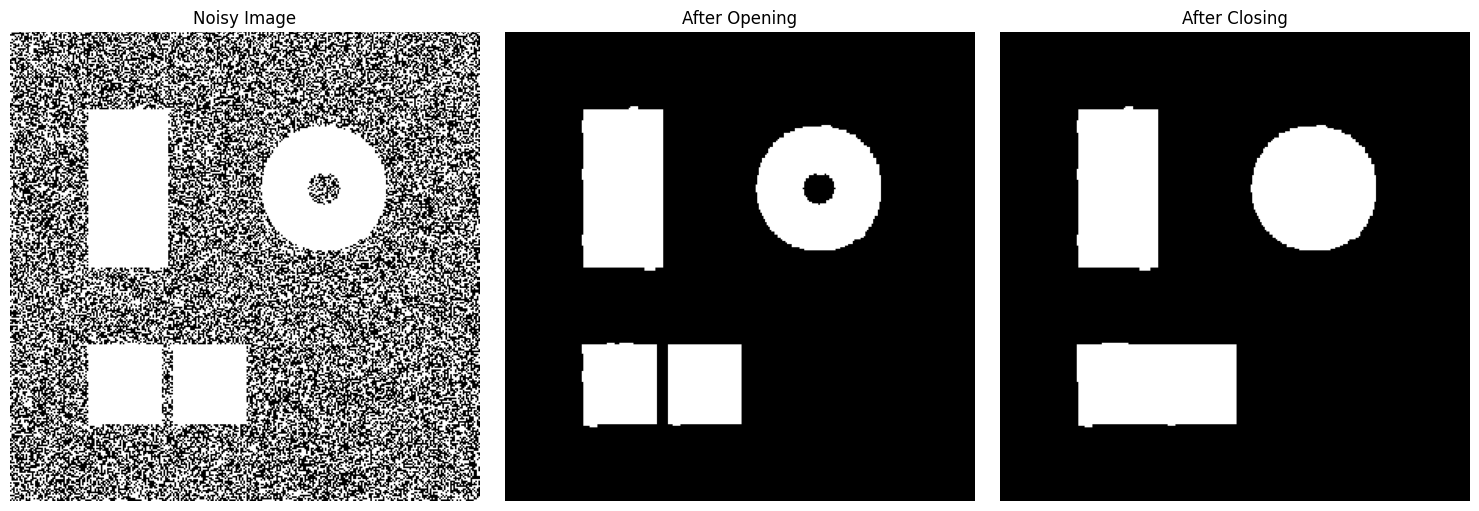

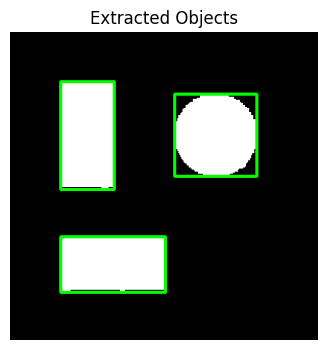

In [8]:
def generate_synthetic_binary():
    img = np.zeros((300, 300), dtype=np.uint8)
    cv2.rectangle(img, (50, 50), (100, 150), 255, -1)
    cv2.circle(img, (200, 100), 40, 255, -1)
    cv2.circle(img, (200, 100), 10, 0, -1) # Hole
    cv2.rectangle(img, (50, 200), (150, 250), 255, -1)
    cv2.line(img, (100, 190), (100, 260), 0, 5) # Break
    noise = np.random.randint(0, 2, (300, 300), dtype=np.uint8) * 255
    img[noise == 255] = 255
    return img

synth_img = generate_synthetic_binary()
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
opened = cv2.morphologyEx(synth_img, cv2.MORPH_OPEN, kernel)
closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15)))

show_images_grid([synth_img, opened, closed],
    ['Noisy Image', 'After Opening', 'After Closing'], 1, 3, cmap='gray', figsize=(15, 5))

def extract_objects(mask):
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(mask, connectivity=8)
    objects = []
    for i in range(1, num_labels):
        area = stats[i, cv2.CC_STAT_AREA]
        if area < 50: continue
        x, y, w, h = stats[i, cv2.CC_STAT_LEFT], stats[i, cv2.CC_STAT_TOP], stats[i, cv2.CC_STAT_WIDTH], stats[i, cv2.CC_STAT_HEIGHT]
        objects.append({'bbox': (x, y, w, h), 'area': area, 'centroid': (centroids[i][0], centroids[i][1]), 'aspect_ratio': round(float(w)/h, 2)})
    return objects

objs = extract_objects(closed)
out_img = cv2.cvtColor(closed, cv2.COLOR_GRAY2BGR)
for obj in objs:
    x, y, w, h = obj['bbox']
    cv2.rectangle(out_img, (x, y), (x+w, y+h), (0, 255, 0), 2)
show_image(out_img, "Extracted Objects")

## Day 5 — Hough Lines & Geometry
**Topics:** HoughLinesP, Line representation, Line angle, Intersection, Point-to-line distance

Geometry Unit Tests Passed!


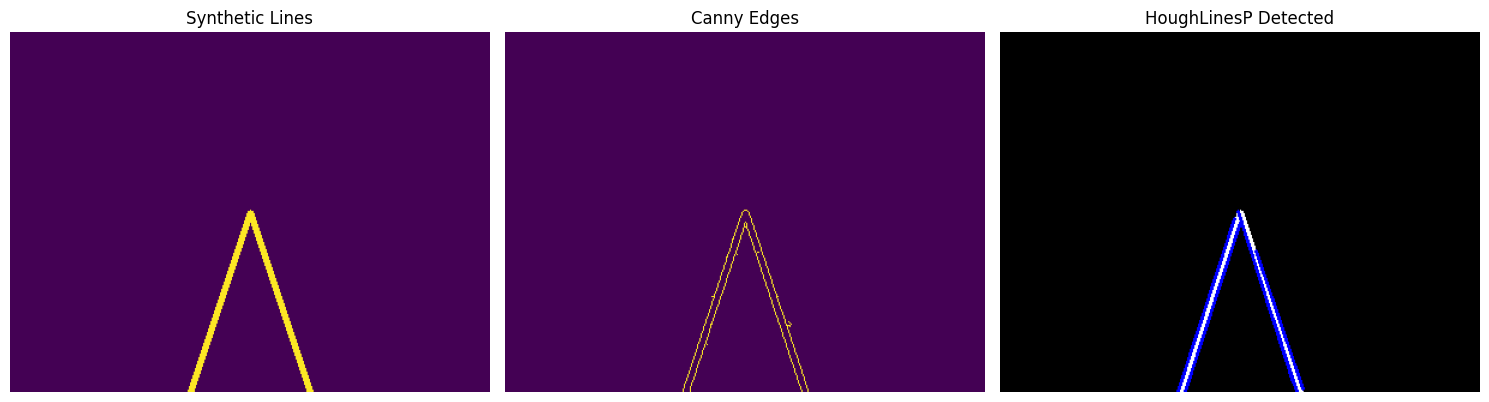

In [13]:
def calculate_line_angle(x1, y1, x2, y2):
    angle = math.degrees(math.atan2(y2 - y1, x2 - x1))
    if angle > 90: angle -= 180
    elif angle < -90: angle += 180
    return angle

def point_to_line_distance(px, py, x1, y1, x2, y2):
    num = abs((x2 - x1) * (y1 - py) - (x1 - px) * (y2 - y1))
    den = math.sqrt((x2 - x1)**2 + (y2 - y1)**2)
    return num / den if den != 0 else 0

def find_intersection(line1, line2):
    x1, y1, x2, y2 = line1
    x3, y3, x4, y4 = line2
    den = (x1 - x2) * (y3 - y4) - (y1 - y2) * (x3 - x4)
    if den == 0: return None
    px = ((x1*y2 - y1*x2)*(x3 - x4) - (x1 - x2)*(x3*y4 - y3*x4)) / den
    py = ((x1*y2 - y1*x2)*(y3 - y4) - (y1 - y2)*(x3*y4 - y3*x4)) / den
    return (px, py)

assert abs(calculate_line_angle(0, 0, 10, 10) - 45.0) < 1e-5
assert abs(point_to_line_distance(0, 5, 0, 0, 10, 0) - 5.0) < 1e-5
print("Geometry Unit Tests Passed!")

img_lines = np.zeros((300, 400), dtype=np.uint8)
cv2.line(img_lines, (150, 300), (200, 150), 255, 3)
cv2.line(img_lines, (250, 300), (200, 150), 255, 3)

# Add noise and detect edges
edges = cv2.Canny(add_gaussian_noise(img_lines, std=10), 50, 150)

# Detect lines using Hough Transform
lines = cv2.HoughLinesP(edges, 1, np.pi/180, threshold=50, minLineLength=40, maxLineGap=10)

out_lines = cv2.cvtColor(img_lines, cv2.COLOR_GRAY2BGR)

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line.flatten()
        cv2.line(out_lines, (x1, y1), (x2, y2), (0, 0, 255), 2)

show_images_grid([img_lines, edges, out_lines], ['Synthetic Lines', 'Canny Edges', 'HoughLinesP Detected'], 1, 3)

## Day 6 — Perspective Transform & Evaluation
**Topics:** Homography, Synthetic Wall Dataset, Line Fitting vs Contours

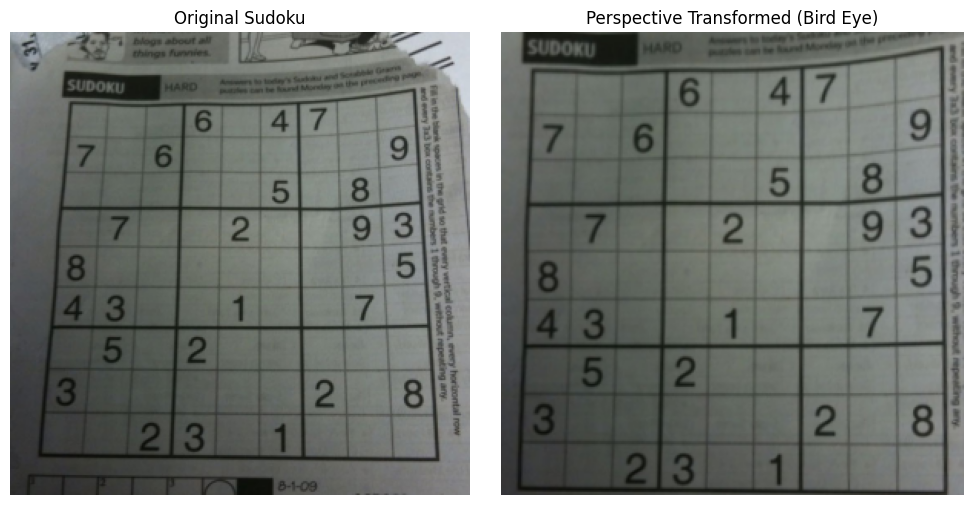

In [10]:
# 1. Perspective Transform (Homography)
img_sudoku = load_image('data/images/sudoku.png')
img_sudoku = resize_keep_ratio(img_sudoku, target_width=300)

# Define source points (corners of the sudoku grid roughly) and destination points
src_pts = np.float32([[23, 27], [275, 30], [8, 280], [290, 280]])
dst_pts = np.float32([[0, 0], [300, 0], [0, 300], [300, 300]])

matrix = cv2.getPerspectiveTransform(src_pts, dst_pts)
img_warped = cv2.warpPerspective(img_sudoku, matrix, (300, 300))

show_images_grid([img_sudoku, img_warped], ['Original Sudoku', 'Perspective Transformed (Bird Eye)'], 1, 2, figsize=(10, 5))

# 2. Synthetic Wall Dataset Generator
def generate_wall_test_set(num_samples=10):
    dataset = []
    for _ in range(num_samples):
        img = np.full((300, 300), 150, dtype=np.uint8)
        gt_angle = random.uniform(-30, 30)
        gt_y_center = random.randint(100, 200)
        rad = math.radians(gt_angle)
        dx, dy = math.cos(rad) * 400, math.sin(rad) * 400
        pt1, pt2 = (int(150 - dx), int(gt_y_center - dy)), (int(150 + dx), int(gt_y_center + dy))
        cv2.fillPoly(img, np.array([[pt1, pt2, (pt2[0], 0), (pt1[0], 0)]], dtype=np.int32), 80)
        img = add_gaussian_noise(img, std=random.uniform(5, 20))
        cv2.line(img, (random.randint(0, 300), 0), (random.randint(0, 300), 300), 120, 2) # Distractor
        dataset.append({'image': img, 'gt_angle': gt_angle, 'gt_y_center': gt_y_center})
    return dataset

test_dataset = generate_wall_test_set(10)

## Day 7 — Phase 1 Project (Expert Pipeline)
**Project:** Wall / Reference Line Detection Pipeline

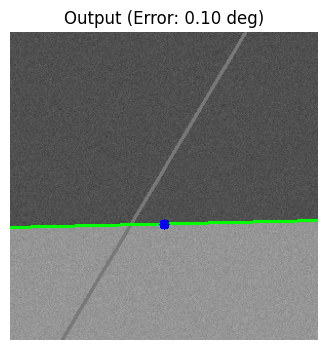

--- EVALUATION REPORT ---\nSuccess Rate: 100.0%\nMean Angle Error: 0.15 deg


In [14]:
def expert_wall_pipeline(image):
    filtered = cv2.bilateralFilter(image, 9, 75, 75)
    v = np.median(filtered)
    edges = cv2.Canny(filtered, int(max(0, (1.0 - 0.33) * v)), int(min(255, (1.0 + 0.33) * v)))
    closed_edges = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, np.ones((3,3), np.uint8))
    
    lines = cv2.HoughLinesP(closed_edges, 1, np.pi/180, 40, minLineLength=60, maxLineGap=20)
    if lines is None: return None
    
    valid_points = []
    for line in lines:
        x1, y1, x2, y2 = line.flatten()
        if abs(calculate_line_angle(x1, y1, x2, y2)) < 45: 
            valid_points.extend([[x1, y1], [x2, y2]])
            
    if not valid_points: return None
    valid_points = np.array(valid_points, dtype=np.int32)
    [vx, vy, x, y] = cv2.fitLine(valid_points, cv2.DIST_L1, 0, 0.01, 0.01)
    
    final_angle = math.degrees(math.atan2(vy[0], vx[0]))
    center_y = (vy[0] / vx[0]) * (150 - x[0]) + y[0]
    return final_angle, center_y, vx[0], vy[0], x[0], y[0]

# --- EVALUATION RUN ---
success_count = 0
angle_errors = []

for i, sample in enumerate(test_dataset):
    img, gt_angle, gt_y = sample['image'], sample['gt_angle'], sample['gt_y_center']
    result = expert_wall_pipeline(img)
    if result:
        success_count += 1
        pred_angle, pred_y, vx, vy, x, y = result
        angle_errors.append(abs(pred_angle - gt_angle))
        
        if success_count == 1:
            annotated = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
            cv2.line(annotated, (int(x - vx*1000), int(y - vy*1000)), (int(x + vx*1000), int(y + vy*1000)), (0, 255, 0), 2)
            cv2.circle(annotated, (150, int(pred_y)), 5, (0,0,255), -1)
            show_image(annotated, f"Output (Error: {abs(pred_angle-gt_angle):.2f} deg)")

print(f"--- EVALUATION REPORT ---\\nSuccess Rate: {success_count / len(test_dataset) * 100:.1f}%\\nMean Angle Error: {np.mean(angle_errors):.2f} deg")